# Income and Sex in the UCI Adult Data: A Statistical Analysis

**Analytical question.** In this dataset, is sex associated with a person’s higher-income target, and how strong is the association?

UCI Adult (Census Income) data drives this analysis. The notebook summarizes the table, compares the income target by sex, investigates the main patterns with figures, and uses a chi-square test of independence. Every value used in the interpretation is printed by a cell.


## Setup

First, I import the analysis libraries and print the versions used by this run. I also set one visible style for every figure so later cells cannot change the display behavior silently.


In [1]:
# Core libraries for the analysis and the figures
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)
os.makedirs("figures", exist_ok=True)  # the four figure cells write here

print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
print("seaborn", sns.__version__, "| scipy", scipy.__version__)

numpy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2
seaborn 0.13.2 | scipy 1.18.1


## Data ingestion

The dataset file sits in the same folder as this notebook. After loading it, I confirm the shape and the first rows, check the types, the missing values, and the duplicates before any analysis.

Source: UCI Machine Learning Repository, Adult (Census Income), donated by Barry Becker and Ronny Kohavi (1996): https://archive.ics.uci.edu/dataset/2/adult.


In [2]:
# Load the dataset that sits beside this notebook
DATA_PATH = "adult.csv"
df = pd.read_csv(DATA_PATH, na_values="?")

print("Shape:", df.shape)
df.head()

Shape: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print(df.dtypes.to_string())
print()

missing = df.isna().sum()
print("Missing values by column:")
print(missing[missing > 0].to_frame("count").to_string())

print("Exact duplicate rows:", int(df.duplicated().sum()))


age               int64
workclass           str
fnlwgt            int64
education           str
education-num     int64
marital-status      str
occupation          str
relationship        str
race                str
sex                 str
capital-gain      int64
capital-loss      int64
hours-per-week    int64
native-country      str
income              str

Missing values by column:
                count
workclass        1836
occupation       1843
native-country    583
Exact duplicate rows: 24


**What the load check shows.**

- **Size and types:** `32,561` rows and `15` columns. `age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, and `hours-per-week` are numeric; the rest are categories.
- **Missing values:** `workclass` `1,836`; `occupation` `1,843`; `native-country` `583`.
- **Duplicates:** `24` exact rows. I keep them because a census extract can legitimately contain two people with identical recorded attributes.
- **Key columns:** `income` and `sex` are complete, so the test below is unaffected.


## Descriptive statistics

In order to understand the table, I summarized the numeric columns, counted the categorical values, and then isolated the variables that matter for the analytical question.


In [4]:
# `fnlwgt` is numeric, so I keep it in the table; 
# the correlation plot below excludes it because it is a census weight, not a measured attribute
numeric_cols = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
df[numeric_cols].describe().round(2)


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32561.00,32561.00,32561.00,32561.00,32561.00,32561.00
mean,38.58,189778.37,10.08,1077.65,87.30,40.44
std,13.64,105549.98,2.57,7385.29,402.96,12.35
min,17.00,12285.00,1.00,0.00,0.00,1.00
25%,28.00,117827.00,9.00,0.00,0.00,40.00
50%,37.00,178356.00,10.00,0.00,0.00,40.00
75%,48.00,237051.00,12.00,0.00,0.00,45.00
max,90.00,1484705.00,16.00,99999.00,4356.00,99.00


In [5]:
cat_cols = ["workclass", "education", "marital-status", "occupation", "relationship", "race", "sex", "native-country", "income"]
cat_summary = pd.DataFrame(
    [
        {
            "column": col,
            "categories": df[col].nunique(dropna=False),
            "missing": df[col].isna().sum(),
            "most common": df[col].value_counts(dropna=False).index[0],
            "count": df[col].value_counts(dropna=False).iloc[0],
            "percent": df[col].value_counts(dropna=False).iloc[0] / len(df) * 100,
        }
        for col in cat_cols
    ]
).set_index("column").round({"percent": 2})

cat_summary


,categories,missing,most common,count,percent
column,,,,,
workclass,9,1836,Private,22696,69.70
education,16,0,HS-grad,10501,32.25
marital-status,7,0,Married-civ-spouse,14976,45.99
occupation,15,1843,Prof-specialty,4140,12.71
relationship,6,0,Husband,13193,40.52
race,5,0,White,27816,85.43
sex,2,0,Male,21790,66.92
native-country,42,583,United-States,29170,89.59
income,2,0,<=50K,24720,75.92


In [6]:
numeric_focus = pd.DataFrame(
    {
        "age": [
            df["age"].mean(),
            df["age"].median(),
            df["age"].skew(),
        ],
        "hours-per-week": [
            df["hours-per-week"].mean(),
            df["hours-per-week"].median(),
            df["hours-per-week"].skew(),
        ],
    },
    index=["mean", "median", "skew"],
).T.round(4)

print("over 50K:", int((df["income"] == ">50K").sum()), "of", len(df), "=", round(100 * (df["income"] == ">50K").mean(), 2), "%")

numeric_focus


over 50K: 7841 of 32561 = 24.08 %


,mean,median,skew
age,38.5816,37.0,0.5587
hours-per-week,40.4375,40.0,0.2276


**What the statistics show.**

- **Age:** right-skewed, with mean `38.5816`, median `37.0`, and skew `0.5587`.
- **Hours:** centered around a `40`-hour week, with mean `40.4375`, median `40.0`, and skew `0.2276`.
- **Income target:** `7,841` people earn over \$50K, `24,720` do not.
- **Sex and race size differences matter for the test below.**


## Visual models

I build four different visual models. Each of these models shows a different angle: `age`, `hours`, `income`, and `correlations`. 
The supporting counts are printed first, so the readings below have a direct source.


In [7]:
# Supporting counts for the readings quoted in the figure and report cells
print("Weekly hours, quartiles by income:")
print(df.groupby("income")["hours-per-week"].quantile([0.25, 0.5, 0.75]).round(1).to_string())
print()
print("Share working past 40 hours, by income (%):")
print((df.groupby("income")["hours-per-week"].apply(lambda s: round(100 * (s > 40).mean(), 1))).to_string())
print()
print("Standard deviations to 4 decimals:")
print("age", round(df["age"].std(), 4), "| hours-per-week", round(df["hours-per-week"].std(), 4))
print()
print("Income gap, male minus female (percentage points):")
rate = df.groupby("sex")["income"].apply(lambda s: (s == ">50K").mean() * 100)
print(round(rate["Male"] - rate["Female"], 2))
print()
print("Zero share (%) for capital-gain and capital-loss:")
print(round(100 * (df["capital-gain"] == 0).mean(), 2), round(100 * (df["capital-loss"] == 0).mean(), 2))
print()
print("Records at age 88 and age 90:")
print(int((df["age"] == 88).sum()), int((df["age"] == 90).sum()))

print("Sex counts:")
print(df["sex"].value_counts().to_string())


Weekly hours, quartiles by income:
income      
<=50K   0.25    35.0
        0.50    40.0
        0.75    40.0
>50K    0.25    40.0
        0.50    40.0
        0.75    50.0

Share working past 40 hours, by income (%):
income
<=50K    23.2
>50K     49.2

Standard deviations to 4 decimals:
age 13.6404 | hours-per-week 12.3474

Income gap, male minus female (percentage points):
19.63

Zero share (%) for capital-gain and capital-loss:
91.67 95.33

Records at age 88 and age 90:
3 43
Sex counts:
sex
Male      21790
Female    10771


### Figure 1 - Distribution of age

**Question:** Where does `age` cluster, and what shape does the spread take?


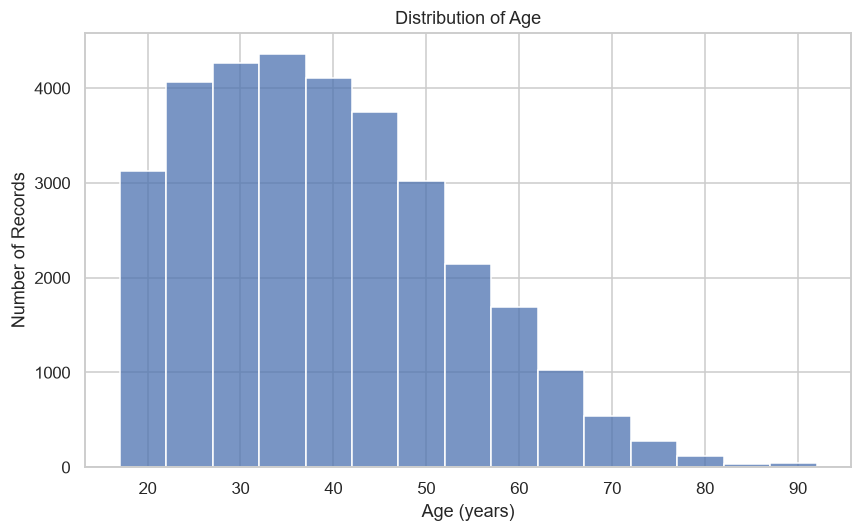

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=range(17, 93, 5), ax=ax)
ax.set_title("Distribution of Age")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of Records")
plt.tight_layout()
plt.savefig("figures/figure-1-age-distribution.png", dpi=110, bbox_inches="tight")
plt.show()
print()

**Answer**: Most records sit before age `50`, with a peak in the late twenties and thirties.

**Analysis**:
- The tail reaches `90`, but that final bin is top-coded at `90`: `43` records sit at `90` against `3` at `88`, so it is not a real cluster.
- Matches the right skew shown by the summary statistics.


### Figure 2 - Hours worked per week by income

**Question:** Do the higher earners work more hours per week?

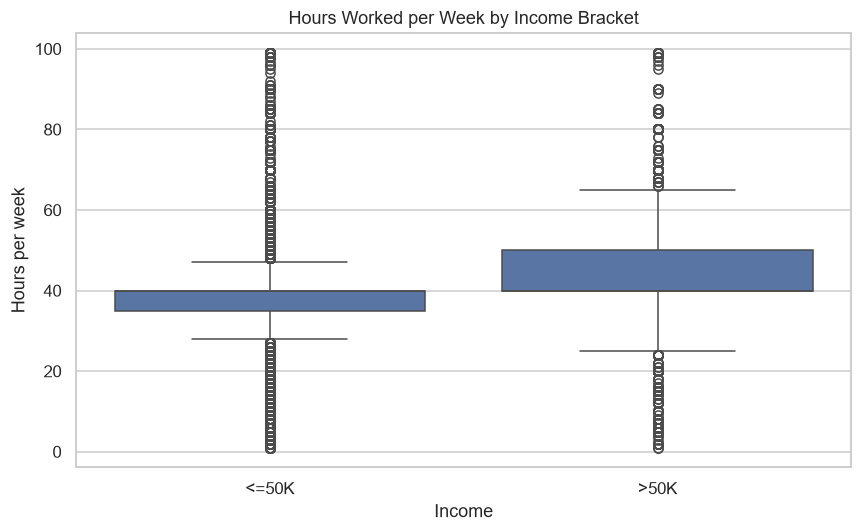

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="income", y="hours-per-week", ax=ax)
ax.set_title("Hours Worked per Week by Income Bracket")
ax.set_xlabel("Income")
ax.set_ylabel("Hours per week")
plt.tight_layout()
plt.savefig("figures/figure-2-hours-by-income.png", dpi=110, bbox_inches="tight")
plt.show()
print()

**Answer**: Both groups share the median of `40` hours, so the change is in the spread.

**Analysis**:
- The higher-earning group sits higher across the quartiles: `40` versus `35`, and `50` versus `40`.
- Its share past `40` hours is roughly twice as common, `49.2%` versus `23.2%`.

**Note**: The figure alone cannot show whether extra hours help explain the gap.


### Figure 3 - Share earning over 50K by sex

**Question:** How wide is the income gap between men and women?

sex
Female    10.95
Male      30.57


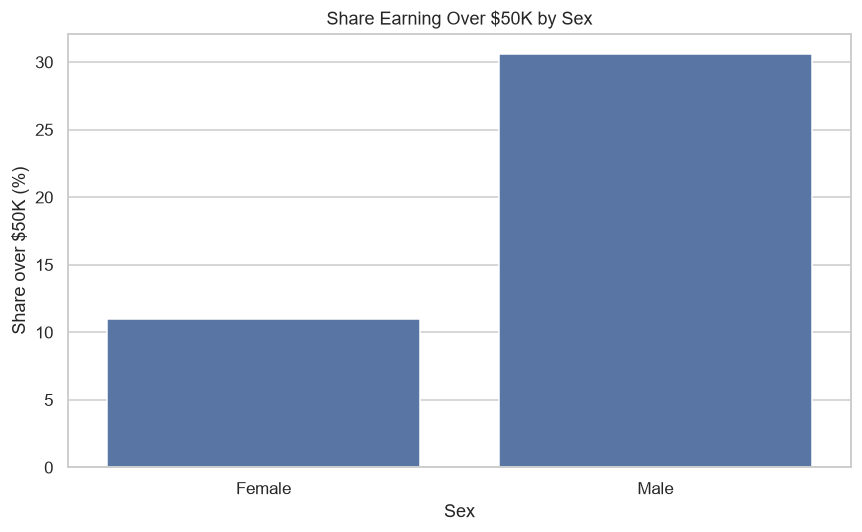

In [10]:
rate = (df.groupby("sex")["income"].apply(lambda s: (s == ">50K").mean() * 100)).round(2)
print(rate.to_string())
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=rate.index, y=rate.values, errorbar=None, ax=ax)
ax.set_title("Share Earning Over $50K by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Share over $50K (%)")
plt.tight_layout()
plt.savefig("figures/figure-3-income-by-sex.png", dpi=110, bbox_inches="tight")
plt.show()
print()


**Answer**: The chart isolates the sex split.

**Analysis**:
- Men earn over \$50K at `30.57%`, women at `10.95%`.
- Gap between men and women is `19.6`%.


### Figure 4 - Correlation heatmap

**Question:** Do the numeric variables move together?

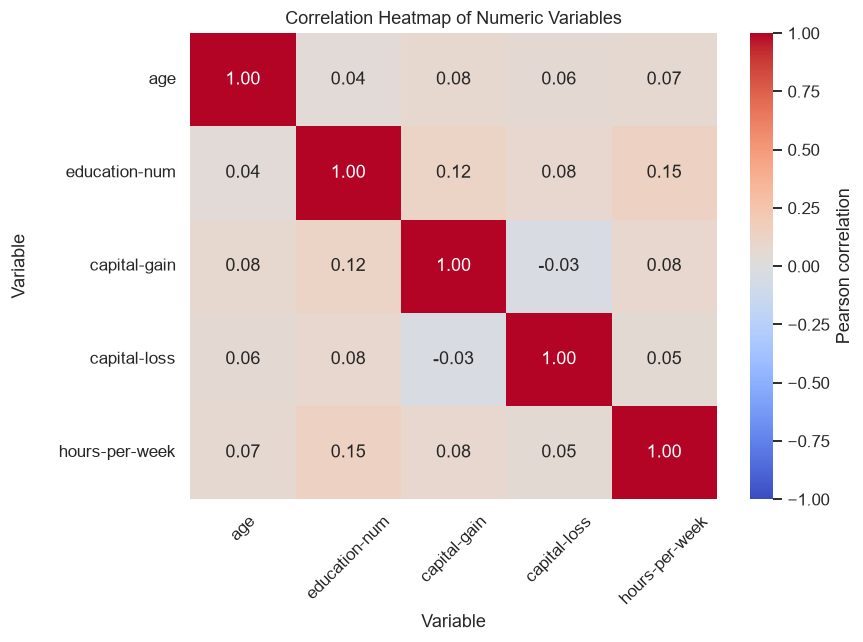

In [11]:
# fnlwgt is a census sampling weight, not a measured attribute, so it is left out
heat_cols = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
fig, ax = plt.subplots(figsize=(8, 6))
corr = df[heat_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Variables")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable", labelpad=20)
ax.tick_params(axis="y", labelrotation=0)
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.savefig("figures/figure-4-correlation-heatmap.png", dpi=110, bbox_inches="tight")
plt.show()
print()

In [12]:
# Print the exact correlations to 4 decimals, so the heatmap values also appear as printed output
print("Pearson correlations among the plotted numeric variables (rounded to 4 decimals):")
print(df[heat_cols].corr().round(4).to_string())
print()

Pearson correlations among the plotted numeric variables (rounded to 4 decimals):
                   age  education-num  capital-gain  capital-loss  hours-per-week
age             1.0000         0.0365        0.0777        0.0578          0.0688
education-num   0.0365         1.0000        0.1226        0.0799          0.1481
capital-gain    0.0777         0.1226        1.0000       -0.0316          0.0784
capital-loss    0.0578         0.0799       -0.0316        1.0000          0.0543
hours-per-week  0.0688         0.1481        0.0784        0.0543          1.0000



**Answer**: The matrix says the numeric variables stay weakly related.

**Analysis**:
- All of the shown **correlations are `weak`**.
- The **strongest links** are between `education-num` and `hours-per-week` (`0.1481`) and between `education-num` and `capital-gain` (`0.1226`).
- The matrix **omits `fnlwgt`**, a census weight, and includes two heavily zero-filled columns: `91.67%` of `capital-gain` and `95.33%` of `capital-loss` are `0`.
- `income` is categorical and outside the matrix, which doesn't really say much about the analytical relationship.

### Comparing the visual models

All four models describe the same dataset from a different angle.

- The **histogram** shows the **age shape**.
- The **box plot** shows **hours by income**.
- The **bar chart** shows **income by sex**.
- The **heatmap** shows **weak correlations** among the numeric variables.

For the main analytical question, the **bar chart** is the clearest support because it directly shows the sex gap and anchors the hypothesis test. The **box plot** is the strongest supporting context because it shows one behavioral difference that could partly explain that gap.

**Note:** <br> **Clearest** means the most direct evidence for the main question. <br>
**Strongest supporting context** means the most useful extra context about what might explain that pattern.

### Chi-square Test of Independence

The chi-square test of independence examines whether two categorical variables are associated. The analysis follows four points:

- **Hypotheses and significance level:** $H_0$ states that the two variables are independent, while $H_1$ states that they are associated. I set the significance level before running the test and compare the resulting p-value against this threshold.
- **Test assumptions:** The test requires independent observations and sufficiently large expected frequencies. I check the expected cell counts against a minimum threshold of `5`. Independence is assessed from the survey design rather than established by the test itself.
- **Interpreting the association:** The chi-square statistic and p-value indicate whether the observed differences provide sufficient evidence against independence. They do not identify which categories account for the association or establish its direction, so I examine the observed counts and proportions to interpret the differences.
- **Effect size and reporting:** Cramér’s V quantifies the strength of the association. I report it alongside the chi-square statistic, degrees of freedom, and p-value.


In [13]:
alpha = 0.05
print(f"Significance level (alpha): {alpha}")

# Chi-square test of independence between sex and income, with Cramér's V
table = pd.crosstab(df["sex"], df["income"])
chi2, _, dof, expected = stats.chi2_contingency(table)  # SciPy applies Yates for 2x2
chi2_pearson, p_value_pearson, _, _ = stats.chi2_contingency(table, correction=False)

n = table.values.sum()
# Cramér's V convention: from the uncorrected Pearson statistic, the reported one
cramers_v = np.sqrt(chi2_pearson / (n * (min(table.shape) - 1)))
cramers_v_yates = np.sqrt(chi2 / (n * (min(table.shape) - 1)))

print("Contingency table (counts):")
print(table.to_string())
print()
print(f"Chi-square statistic, Pearson uncorrected (reported): {chi2_pearson:.4f}")
print(f"Chi-square statistic, Yates-corrected (SciPy default): {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
if p_value_pearson > 0:
    print(f"p-value: {p_value_pearson:.4e}")
else:
    # chi-square with 1 dof: p = erfc(sqrt(chi2/2)); the value underflows, so
    # report its order of magnitude from the asymptotic erfc
    z = np.sqrt(chi2_pearson / 2)
    log10_p = -(z**2) / np.log(10) - np.log10(z) - 0.5 * np.log10(np.pi)
    print(f"p-value: about 1e{int(round(log10_p))} (far below 1e-300)")
print(f"Smallest expected count: {expected.min():.2f}")
print(f"Cramér's V (from the Pearson statistic): {cramers_v:.4f}")
print(f"Cramér's V (Yates-corrected variant): {cramers_v_yates:.4f}")

print(f"Cramér's V squared: {cramers_v ** 2:.4f} ({100 * cramers_v ** 2:.1f}%)")


Significance level (alpha): 0.05
Contingency table (counts):
income  <=50K  >50K
sex                
Female   9592  1179
Male    15128  6662

Chi-square statistic, Pearson uncorrected (reported): 1518.8868
Chi-square statistic, Yates-corrected (SciPy default): 1517.8134
Degrees of freedom: 1
p-value: about 1e-332 (far below 1e-300)
Smallest expected count: 2593.76
Cramér's V (from the Pearson statistic): 0.2160
Cramér's V (Yates-corrected variant): 0.2159
Cramér's V squared: 0.0466 (4.7%)


**Assumptions and limitations**

The minimum expected count, `2593.76`, is large enough for the chi-square approximation to be appropriate.

However, the `relationship` column suggests that some rows may represent people from the same household or family, so their observations may not be independent. The dataset is also an extract rather than a random sample, which limits how confidently the findings generalize. As discussed by Agresti (2007), dependence between observations can affect the validity of standard chi-square inference. So I read the p-value carefully rather than taking it at face value.

In [14]:
# Show the expected counts to confirm the smallest one is well above 5
expected_df = pd.DataFrame(expected, index=table.index, columns=table.columns)
print("Expected counts:")
print(expected_df.round(2).to_string())
print("Minimum expected count:", round(expected.min(), 2))

Expected counts:
income     <=50K     >50K
sex                      
Female   8177.24  2593.76
Male    16542.76  5247.24
Minimum expected count: 2593.76


In [15]:
# Difference in the over-50K rate by sex, normal-approximation 95% confidence interval
female_over, female_n = table.loc["Female", ">50K"], table.loc["Female"].sum()
male_over, male_n = table.loc["Male", ">50K"], table.loc["Male"].sum()
p_female, p_male = female_over / female_n, male_over / male_n
gap = p_male - p_female
se = np.sqrt(p_male * (1 - p_male) / male_n + p_female * (1 - p_female) / female_n)
print(f"Gap (male minus female): {100 * gap:.2f} percentage points")
print(f"95% confidence interval: [{100 * (gap - 1.96 * se):.2f}, {100 * (gap + 1.96 * se):.2f}]")

Gap (male minus female): 19.63 percentage points
95% confidence interval: [18.78, 20.48]


### Test interpretation

**Answer:** Sex and income are not independent.

**Analysis**:
- The uncorrected Pearson chi-square is `1518.8868` with `1` degree of freedom, and the p-value is far below `1e-300`.
- SciPy's default Yates-corrected statistic is `1517.8134`, with the same conclusion.
- The smallest expected count is `2593.76`, so the count-based approximation is safe.
- Cramér's V is `0.2160`, and V squared is `0.0466` (`4.7%`), a modest association.
- The observed gap is `19.63` percentage points, with a 95% interval from `18.78` to `20.48`.

**Note**: This result describes the data. It does not separate occupation, education, hours, or broader labour-market effects.
